In [5]:
import zipfile
import os

zip_path = "/content/archive (1).zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/car_dataset")

print(os.listdir("/content/car_dataset"))

['used_car_price_dataset_extended.csv']


In [6]:
import pandas as pd

df = pd.read_csv("/content/car_dataset/used_car_price_dataset_extended.csv")

print(df.head())

   make_year  mileage_kmpl  engine_cc fuel_type  owner_count  price_usd  \
0       2001          8.17       4000    Petrol            4    8587.64   
1       2014         17.59       1500    Petrol            4    5943.50   
2       2023         18.09       2500    Diesel            5    9273.58   
3       2009         11.28        800    Petrol            1    6836.24   
4       2005         12.23       1000    Petrol            2    4625.79   

       brand transmission  color service_history  accidents_reported  \
0  Chevrolet       Manual  White             NaN                   0   
1      Honda       Manual  Black             NaN                   0   
2        BMW    Automatic  Black            Full                   1   
3    Hyundai       Manual   Blue            Full                   0   
4     Nissan    Automatic    Red            Full                   0   

  insurance_valid  
0              No  
1             Yes  
2             Yes  
3             Yes  
4             Ye

In [7]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (10000, 12)

Column Names:
Index(['make_year', 'mileage_kmpl', 'engine_cc', 'fuel_type', 'owner_count',
       'price_usd', 'brand', 'transmission', 'color', 'service_history',
       'accidents_reported', 'insurance_valid'],
      dtype='object')

Missing Values:
make_year                0
mileage_kmpl             0
engine_cc                0
fuel_type                0
owner_count              0
price_usd                0
brand                    0
transmission             0
color                    0
service_history       2038
accidents_reported       0
insurance_valid          0
dtype: int64


In [8]:
df = df.dropna()

print("Dataset after cleaning:", df.shape)
print("Missing values after cleaning:")
print(df.isnull().sum())

Dataset after cleaning: (7962, 12)
Missing values after cleaning:
make_year             0
mileage_kmpl          0
engine_cc             0
fuel_type             0
owner_count           0
price_usd             0
brand                 0
transmission          0
color                 0
service_history       0
accidents_reported    0
insurance_valid       0
dtype: int64


In [9]:
print(df.describe())

         make_year  mileage_kmpl    engine_cc  owner_count     price_usd  \
count  7962.000000   7962.000000  7962.000000  7962.000000   7962.000000   
mean   2009.153605     17.935750  2296.156745     2.984426   7194.356988   
std       8.340053      5.032935  1291.935427     1.416524   2803.590607   
min    1995.000000      5.000000   800.000000     1.000000   1000.000000   
25%    2002.000000     14.500000  1200.000000     2.000000   5177.290000   
50%    2009.000000     17.940000  2000.000000     3.000000   6971.060000   
75%    2016.000000     21.330000  3000.000000     4.000000   9023.552500   
max    2023.000000     35.000000  5000.000000     5.000000  17647.630000   

       accidents_reported  
count         7962.000000  
mean             0.500502  
std              0.697088  
min              0.000000  
25%              0.000000  
50%              0.000000  
75%              1.000000  
max              5.000000  


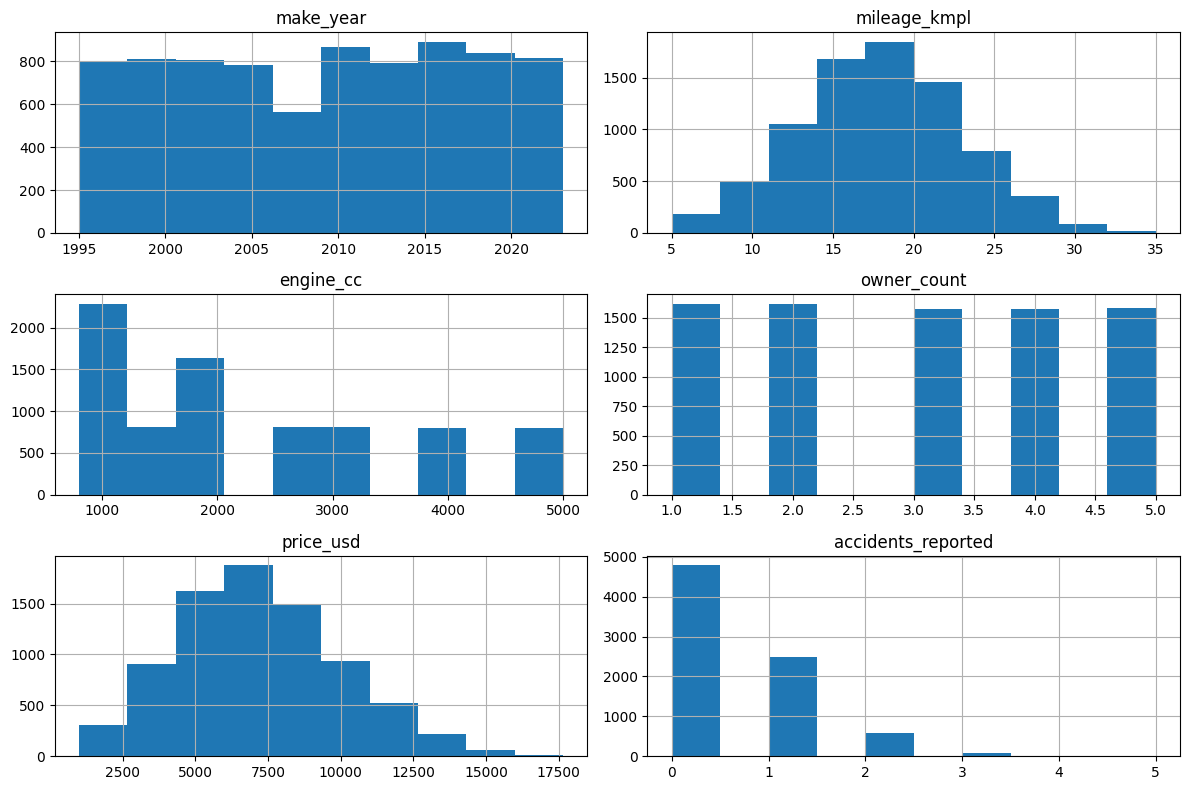

In [10]:
import matplotlib.pyplot as plt

df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

In [11]:
print(df.columns.tolist())

['make_year', 'mileage_kmpl', 'engine_cc', 'fuel_type', 'owner_count', 'price_usd', 'brand', 'transmission', 'color', 'service_history', 'accidents_reported', 'insurance_valid']


In [12]:
X = df.drop("price_usd", axis=1)
y = df["price_usd"]

print("Input Features:", X.shape)
print("Target:", y.shape)

Input Features: (7962, 11)
Target: (7962,)


In [13]:
X = pd.get_dummies(X, drop_first=True)

print("Converted Input Shape:", X.shape)
print(X.head())

Converted Input Shape: (7962, 24)
   make_year  mileage_kmpl  engine_cc  owner_count  accidents_reported  \
2       2023         18.09       2500            5                   1   
3       2009         11.28        800            1                   0   
4       2005         12.23       1000            2                   0   
5       2002         13.77       2500            4                   1   
6       2023         12.50       1000            3                   0   

   fuel_type_Electric  fuel_type_Petrol  brand_Chevrolet  brand_Ford  \
2               False             False            False       False   
3               False              True            False       False   
4               False              True            False       False   
5               False             False            False       False   
6               False              True            False       False   

   brand_Honda  ...  brand_Toyota  brand_Volkswagen  transmission_Manual  \
2        Fal

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (6369, 24)
Testing Data: (1593, 24)


In [15]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [16]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error: 797.6547752465476
R2 Score: 0.8693707788083219


In [17]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0       6996.80      5743.598677
1       7863.82      7847.974676
2       4616.83      6448.990063
3      10690.80     10777.726719
4      13272.05     11738.025277
5       8147.47      8210.882853
6       6495.58      6078.468109
7       7562.05      5699.285210
8       6398.21      7057.318988
9      10543.65     10237.752500


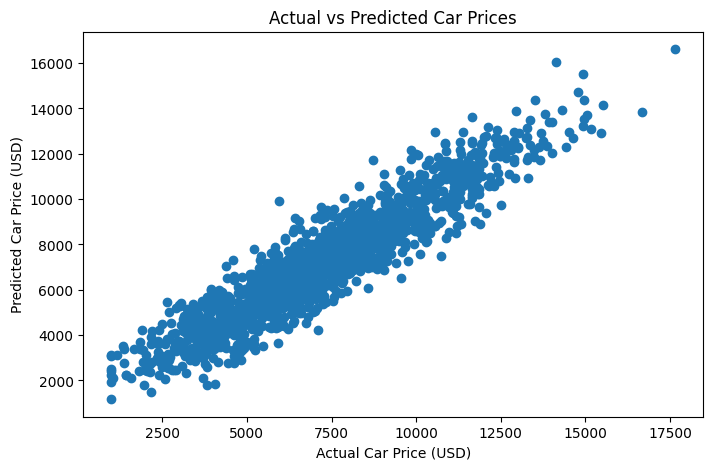

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Car Price (USD)")
plt.ylabel("Predicted Car Price (USD)")
plt.title("Actual vs Predicted Car Prices")
plt.show()

## Conclusion

In this project, we developed a Car Price Prediction model using Machine Learning. We used the Linear Regression algorithm to predict car prices based on car features such as manufacturing year, mileage, engine capacity, fuel type, and brand.

We evaluated the model using Mean Absolute Error (MAE) and R² Score. The model helps estimate the price of a used car based on its features.